# GoTyme Case Study Interview 

The main aim of the model is to classify whether a customer will take up the sales offer or not when we cold call them, so the better we discriminate between who will be more likely to 
take up the offer and who will not, can help our client to better optimise their internal efforts in terms of cold calling the right customer in order to convert those calls to sales
The secondary aim, is to overlay the revenue / cost impacts based on our classification outcomes, in order to evaluate what the estimated impact will be on the financials by executing campaigns
using this model for selection purposes and what it will yield and cost us

In [27]:
# Things to consider
# - Check whether all the input variables are relevant to be considered for use in the model
# - Can you explain what your data looks like and whether there are some outliers or corrections which have to be done
# - How do you check whether there exist any discriminating power amongst the variables
#  - How do you control for high correlations amongst your variables
#  - Do you care whether the response variable classes are balanced or not
# - Do you mind having variables all at different scales
# - How do you encode categorical data and do you group any of these
# - Do you bin your numerical data or not?
# - Do you split your data for training and testing?
# - Do you perform validation checks as you train your models
# - How do you decide which model is the best one to use?
# - How do you ensure the model does not over / underfit the data and that it can be used for prediction purposes?
# - How do you know which input variables are the most and least important?
# - Do you fit different models and how do you decide which one to optimize?
# - How do you optimize your selected model? Why did you choose to optimize it that way?
# - How do you settle on which cut off hurdle to use in terms of classifying new data into a 1 or 0?
# - How do you interpret the confusion matrix obtained by the final model?


In [28]:
# Bonus question:				
# The Finance, Sales and Risk teams have a vested interest in trying to figure out the potential impact a sales campaign will have to see that we can justify the cost / benefit of running the campaign				
# The sales team have obtained a list of prospective customers from a data provider which contains 10,000 records.				
# The expectation is, that we will be utilising the newly created response model you have developed and apply it to the list in order to identify who we should call and who we shouldn't				
# Assume for now, that the predictions in terms of the confusion matrix of the 10,000 campaign list, follows the same percentages as per your development sample in terms of the confusion matrix				
                
# Assuming 100% approval rates (i.e. everyone we call qualifies for a credit product), the risk team has overlaid their predictions on the 10,000 customer list, 				
# and they have classified the customers accordingly into the following 3 risk bands  				
#         Risk distrubution		
#     High	10%		
#     Medium	25%		
#     Low	65%		
                
# The Finance team has further broken down the net profit estimates for each of the risk bands based on whether we have a successful offer taken up (sale) or not (not interested)				
#         Taken up	Non taken up	
#     High	 285.00 	-300.00 	
#     Medium	 705.00 	-300.00 	
#     Low	 1,225.00 	-300.00 	
                
# By using your confusion matrix, can you calculate the 				
# a) Expected net profit we stand to make by running this campaign on the customers we intent to phone?				


In [29]:
# Assuming 100% approval rates (i.e. everyone we call qualifies for a credit product), the risk team has overlaid their predictions on the 10,000 customer list, 
# and they have classified the customers accordingly into the following 3 risk bands  


# The Finance team has further broken down the net profit estimates for each of the risk bands based on whether we have a successful offer taken up (sale) or not (not interested)


# By using your confusion matrix, can you calculate the 
# a) Expected net profit we stand to make by running this campaign on the customers we intent to phone?
# b) What is the lost opportunity of net profit due to us misclassifying customers by using your response model?


## Dataset Overview

In [30]:
import pandas as pd
df = pd.read_csv('dataset.csv', sep='|')

print("Dataset shape:", df.shape)
df.info()
df.head()

Dataset shape: (35000, 21)
<class 'pandas.DataFrame'>
RangeIndex: 35000 entries, 0 to 34999
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Feature_ae_0   35000 non-null  int64  
 1   Feature_dn_1   35000 non-null  int64  
 2   Feature_cn_2   35000 non-null  int64  
 3   Feature_ps_3   35000 non-null  int64  
 4   Feature_ps_4   35000 non-null  int64  
 5   Feature_ee_5   35000 non-null  float64
 6   Feature_cx_6   35000 non-null  float64
 7   Feature_cx_7   35000 non-null  float64
 8   Feature_em_8   35000 non-null  float64
 9   Feature_nd_9   35000 non-null  float64
 10  Feature_jd_10  35000 non-null  str    
 11  Feature_md_11  35000 non-null  str    
 12  Feature_ed_12  35000 non-null  str    
 13  Feature_dd_13  35000 non-null  str    
 14  Feature_hd_14  35000 non-null  str    
 15  Feature_ld_15  35000 non-null  str    
 16  Feature_cd_16  35000 non-null  str    
 17  Feature_md_17  35000 non-null  str

,Feature_ae_0,Feature_dn_1,Feature_cn_2,Feature_ps_3,Feature_ps_4,Feature_ee_5,Feature_cx_6,Feature_cx_7,Feature_em_8,Feature_nd_9,...,Feature_md_11,Feature_ed_12,Feature_dd_13,Feature_hd_14,Feature_ld_15,Feature_cd_16,Feature_md_17,Feature_dd_18,Feature_pd_19,Response
0,57,371,1,999,1,-1.8,92.893,-46.2,1.299,5099.1,...,Cat_1_m***d,Cat_3_h***l,Cat_0_n***o,Cat_0_n***o,Cat_2_y***s,Cat_0_c***r,Cat_6_m***y,Cat_1_m***n,Cat_0_f***e,0
1,55,285,2,999,0,1.1,93.994,-36.4,4.860,5191.0,...,Cat_1_m***d,Cat_7_u***n,Cat_1_u***n,Cat_2_y***s,Cat_0_n***o,Cat_1_t***e,Cat_6_m***y,Cat_2_t***u,Cat_1_n***t,0
2,33,52,1,999,1,-1.8,92.893,-46.2,1.313,5099.1,...,Cat_1_m***d,Cat_2_b***y,Cat_0_n***o,Cat_0_n***o,Cat_0_n***o,Cat_0_c***r,Cat_6_m***y,Cat_0_f***i,Cat_0_f***e,0
3,36,355,4,999,0,1.4,94.465,-41.8,4.967,5228.1,...,Cat_1_m***d,Cat_3_h***l,Cat_0_n***o,Cat_0_n***o,Cat_0_n***o,Cat_1_t***e,Cat_4_j***n,Cat_0_f***i,Cat_1_n***t,0
4,27,189,2,999,0,1.4,93.918,-42.7,4.963,5228.1,...,Cat_1_m***d,Cat_3_h***l,Cat_0_n***o,Cat_2_y***s,Cat_0_n***o,Cat_0_c***r,Cat_3_j***l,Cat_0_f***i,Cat_1_n***t,0


## Renaming Column Names based on Data Dictionary 

In [31]:
# Rename columns using the provided data dictionary for readability while working with the dataset
column_mapping = {
    "Feature_ae_0": "customer_age",
    "Feature_dn_1": "last_call_duration_seconds",
    "Feature_cn_2": "call_attempts",
    "Feature_ps_3": "days_since_last_campaign",
    "Feature_ps_4": "prev_campaign_call_attempts",
    "Feature_ee_5": "employment_variation_rate_q",
    "Feature_cx_6": "consumer_price_index_m",
    "Feature_cx_7": "consumer_confidence_index_m",
    "Feature_em_8": "interbank_rate_3m_q",
    "Feature_nd_9": "num_employees_q",
    "Feature_jd_10": "employment_type",
    "Feature_md_11": "customer_civil_status",
    "Feature_ed_12": "education_level",
    "Feature_dd_13": "credit_facility_default",
    "Feature_hd_14": "has_home_loan",
    "Feature_ld_15": "has_personal_loan",
    "Feature_cd_16": "contact_medium",
    "Feature_md_17": "last_contact_month",
    "Feature_dd_18": "last_contact_weekday",
    "Feature_pd_19": "previous_campaign_outcome",
    "Response": "response"
}

df = df.rename(columns=column_mapping)

# Optional: preview renamed columns
print(df.columns.tolist())

df.head(10)

['customer_age', 'last_call_duration_seconds', 'call_attempts', 'days_since_last_campaign', 'prev_campaign_call_attempts', 'employment_variation_rate_q', 'consumer_price_index_m', 'consumer_confidence_index_m', 'interbank_rate_3m_q', 'num_employees_q', 'employment_type', 'customer_civil_status', 'education_level', 'credit_facility_default', 'has_home_loan', 'has_personal_loan', 'contact_medium', 'last_contact_month', 'last_contact_weekday', 'previous_campaign_outcome', 'response']


,customer_age,last_call_duration_seconds,call_attempts,days_since_last_campaign,prev_campaign_call_attempts,employment_variation_rate_q,consumer_price_index_m,consumer_confidence_index_m,interbank_rate_3m_q,num_employees_q,...,customer_civil_status,education_level,credit_facility_default,has_home_loan,has_personal_loan,contact_medium,last_contact_month,last_contact_weekday,previous_campaign_outcome,response
0,57,371,1,999,1,-1.8,92.893,-46.2,1.299,5099.1,...,Cat_1_m***d,Cat_3_h***l,Cat_0_n***o,Cat_0_n***o,Cat_2_y***s,Cat_0_c***r,Cat_6_m***y,Cat_1_m***n,Cat_0_f***e,0
1,55,285,2,999,0,1.1,93.994,-36.4,4.860,5191.0,...,Cat_1_m***d,Cat_7_u***n,Cat_1_u***n,Cat_2_y***s,Cat_0_n***o,Cat_1_t***e,Cat_6_m***y,Cat_2_t***u,Cat_1_n***t,0
2,33,52,1,999,1,-1.8,92.893,-46.2,1.313,5099.1,...,Cat_1_m***d,Cat_2_b***y,Cat_0_n***o,Cat_0_n***o,Cat_0_n***o,Cat_0_c***r,Cat_6_m***y,Cat_0_f***i,Cat_0_f***e,0
3,36,355,4,999,0,1.4,94.465,-41.8,4.967,5228.1,...,Cat_1_m***d,Cat_3_h***l,Cat_0_n***o,Cat_0_n***o,Cat_0_n***o,Cat_1_t***e,Cat_4_j***n,Cat_0_f***i,Cat_1_n***t,0
4,27,189,2,999,0,1.4,93.918,-42.7,4.963,5228.1,...,Cat_1_m***d,Cat_3_h***l,Cat_0_n***o,Cat_2_y***s,Cat_0_n***o,Cat_0_c***r,Cat_3_j***l,Cat_0_f***i,Cat_1_n***t,0
5,58,605,1,999,0,1.4,93.918,-42.7,4.962,5228.1,...,Cat_1_m***d,Cat_5_p***e,Cat_0_n***o,Cat_2_y***s,Cat_2_y***s,Cat_0_c***r,Cat_3_j***l,Cat_0_f***i,Cat_1_n***t,0
6,48,243,1,999,0,1.1,93.994,-36.4,4.856,5191.0,...,Cat_1_m***d,Cat_3_h***l,Cat_1_u***n,Cat_2_y***s,Cat_0_n***o,Cat_1_t***e,Cat_6_m***y,Cat_4_w***d,Cat_1_n***t,0
7,51,24,7,999,0,1.4,93.444,-36.1,4.962,5228.1,...,Cat_0_d***d,Cat_6_u***e,Cat_1_u***n,Cat_2_y***s,Cat_0_n***o,Cat_0_c***r,Cat_1_a***g,Cat_2_t***u,Cat_1_n***t,0
8,24,126,4,999,0,1.4,94.465,-41.8,4.962,5228.1,...,Cat_1_m***d,Cat_6_u***e,Cat_0_n***o,Cat_2_y***s,Cat_2_y***s,Cat_1_t***e,Cat_4_j***n,Cat_4_w***d,Cat_1_n***t,0
9,36,43,4,999,0,1.4,93.918,-42.7,4.962,5228.1,...,Cat_0_d***d,Cat_5_p***e,Cat_0_n***o,Cat_2_y***s,Cat_2_y***s,Cat_0_c***r,Cat_3_j***l,Cat_1_m***n,Cat_1_n***t,0


# Exploratory Data Analysis

## Missing Values

In [32]:
print("Missing values:")
print(df.isna().sum())

Missing values:
customer_age                   0
last_call_duration_seconds     0
call_attempts                  0
days_since_last_campaign       0
prev_campaign_call_attempts    0
employment_variation_rate_q    0
consumer_price_index_m         0
consumer_confidence_index_m    0
interbank_rate_3m_q            0
num_employees_q                0
employment_type                0
customer_civil_status          0
education_level                0
credit_facility_default        0
has_home_loan                  0
has_personal_loan              0
contact_medium                 0
last_contact_month             0
last_contact_weekday           0
previous_campaign_outcome      0
response                       0
dtype: int64


## Duplicates

In [33]:
print("Duplicated values:")
print(df.duplicated().sum())

Duplicated values:
11


In [34]:
duplicates = df[df.duplicated(keep=False)]

print("Rows involved in duplicates:", len(duplicates))
display(duplicates.sort_values(by=df.columns.tolist()))

Rows involved in duplicates: 22


,customer_age,last_call_duration_seconds,call_attempts,days_since_last_campaign,prev_campaign_call_attempts,employment_variation_rate_q,consumer_price_index_m,consumer_confidence_index_m,interbank_rate_3m_q,num_employees_q,...,customer_civil_status,education_level,credit_facility_default,has_home_loan,has_personal_loan,contact_medium,last_contact_month,last_contact_weekday,previous_campaign_outcome,response
13767,24,114,1,999,0,-1.8,93.075,-47.1,1.423,5099.1,...,Cat_2_s***e,Cat_3_h***l,Cat_0_n***o,Cat_2_y***s,Cat_0_n***o,Cat_0_c***r,Cat_0_a***r,Cat_3_t***e,Cat_1_n***t,0
34582,24,114,1,999,0,-1.8,93.075,-47.1,1.423,5099.1,...,Cat_2_s***e,Cat_3_h***l,Cat_0_n***o,Cat_2_y***s,Cat_0_n***o,Cat_0_c***r,Cat_0_a***r,Cat_3_t***e,Cat_1_n***t,0
16751,27,331,2,999,0,1.4,93.918,-42.7,4.962,5228.1,...,Cat_2_s***e,Cat_5_p***e,Cat_0_n***o,Cat_0_n***o,Cat_0_n***o,Cat_0_c***r,Cat_3_j***l,Cat_1_m***n,Cat_1_n***t,0
22628,27,331,2,999,0,1.4,93.918,-42.7,4.962,5228.1,...,Cat_2_s***e,Cat_5_p***e,Cat_0_n***o,Cat_0_n***o,Cat_0_n***o,Cat_0_c***r,Cat_3_j***l,Cat_1_m***n,Cat_1_n***t,0
8359,32,128,1,999,0,1.4,93.918,-42.7,4.968,5228.1,...,Cat_2_s***e,Cat_5_p***e,Cat_0_n***o,Cat_2_y***s,Cat_0_n***o,Cat_0_c***r,Cat_3_j***l,Cat_2_t***u,Cat_1_n***t,0
13226,32,128,1,999,0,1.4,93.918,-42.7,4.968,5228.1,...,Cat_2_s***e,Cat_5_p***e,Cat_0_n***o,Cat_2_y***s,Cat_0_n***o,Cat_0_c***r,Cat_3_j***l,Cat_2_t***u,Cat_1_n***t,0
7458,35,348,4,999,0,-1.8,92.893,-46.2,1.313,5099.1,...,Cat_1_m***d,Cat_6_u***e,Cat_0_n***o,Cat_2_y***s,Cat_0_n***o,Cat_0_c***r,Cat_6_m***y,Cat_0_f***i,Cat_1_n***t,0
15237,35,348,4,999,0,-1.8,92.893,-46.2,1.313,5099.1,...,Cat_1_m***d,Cat_6_u***e,Cat_0_n***o,Cat_2_y***s,Cat_0_n***o,Cat_0_c***r,Cat_6_m***y,Cat_0_f***i,Cat_1_n***t,0
11483,36,88,1,999,0,1.4,93.918,-42.7,4.966,5228.1,...,Cat_1_m***d,Cat_7_u***n,Cat_0_n***o,Cat_0_n***o,Cat_0_n***o,Cat_1_t***e,Cat_3_j***l,Cat_2_t***u,Cat_1_n***t,0
30101,36,88,1,999,0,1.4,93.918,-42.7,4.966,5228.1,...,Cat_1_m***d,Cat_7_u***n,Cat_0_n***o,Cat_0_n***o,Cat_0_n***o,Cat_1_t***e,Cat_3_j***l,Cat_2_t***u,Cat_1_n***t,0


In [35]:
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)

(34989, 21)


## Target Distribution

In [36]:
df["response"].value_counts()
df["response"].value_counts(normalize=True)

response
0    0.887708
1    0.112292
Name: proportion, dtype: float64

## Correllation

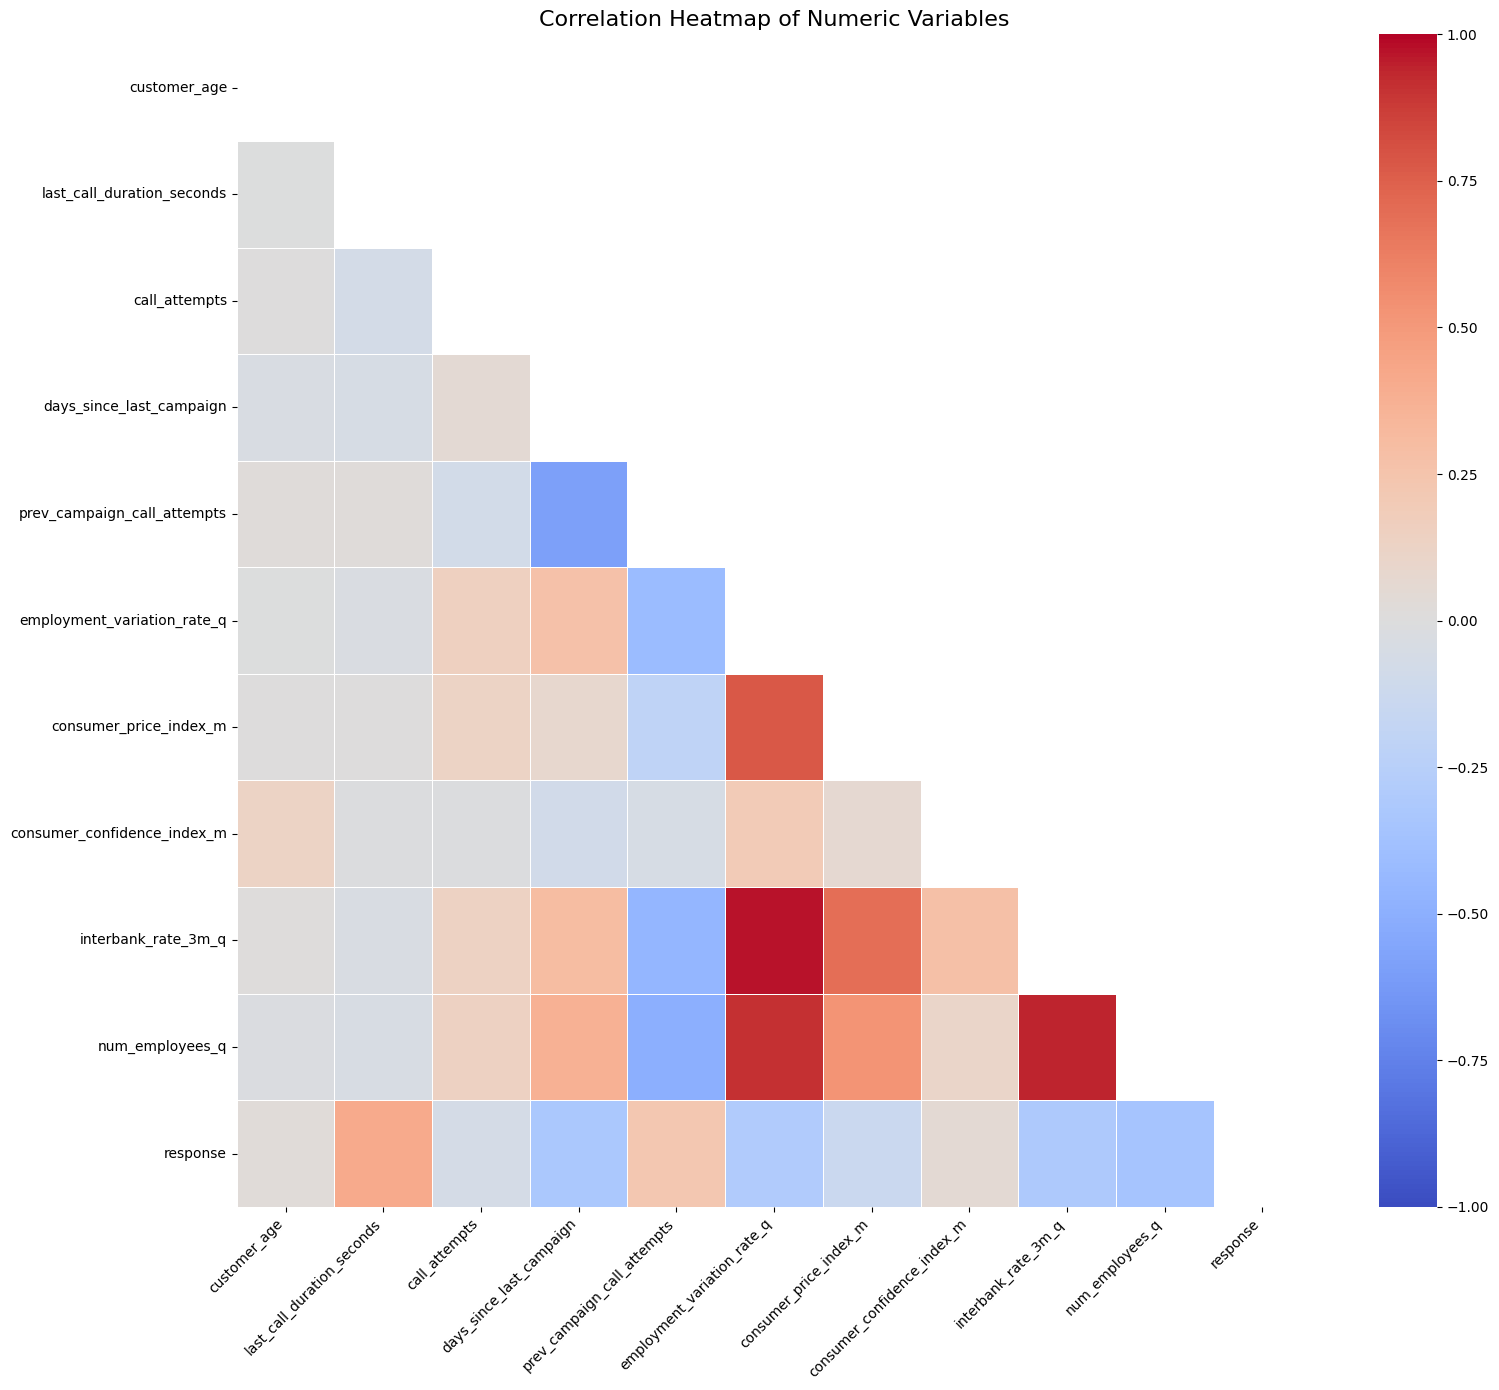

In [37]:
import numpy as np
import seaborn as sns

import matplotlib.pyplot as plt

# Keep only numeric columns for the correlation heatmap
numeric_df = df.select_dtypes(include=["number"])

# Correlation matrix
corr = numeric_df.corr()

# Plot
plt.figure(figsize=(16, 14))
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(
    corr,
    mask=mask,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    annot=False,
    linewidths=0.5,
    square=False
)

plt.title("Correlation Heatmap of Numeric Variables", fontsize=16)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Non-categorical 


In [38]:
non_cat_cols = df.select_dtypes(exclude=["object", "string", "category"]).columns.tolist()
print("Non-categorical variables:")
display(non_cat_cols)

Non-categorical variables:


['customer_age',
 'last_call_duration_seconds',
 'call_attempts',
 'days_since_last_campaign',
 'prev_campaign_call_attempts',
 'employment_variation_rate_q',
 'consumer_price_index_m',
 'consumer_confidence_index_m',
 'interbank_rate_3m_q',
 'num_employees_q',
 'response']

In [39]:
df[non_cat_cols].describe()

,customer_age,last_call_duration_seconds,call_attempts,days_since_last_campaign,prev_campaign_call_attempts,employment_variation_rate_q,consumer_price_index_m,consumer_confidence_index_m,interbank_rate_3m_q,num_employees_q,response
count,34989.000000,34989.000000,34989.000000,34989.000000,34989.000000,34989.000000,34989.000000,34989.000000,34989.000000,34989.000000,34989.000000
mean,40.030238,257.870645,2.562520,962.420532,0.173769,0.080785,93.575856,-40.519472,3.619997,5167.038398,0.112292
std,10.427325,258.615788,2.767745,187.040455,0.495074,1.570988,0.578551,4.619486,1.734564,72.170909,0.315730
min,17.000000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000,0.000000
25%,32.000000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000,0.000000
50%,38.000000,179.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000,0.000000
75%,47.000000,318.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000,0.000000
max,98.000000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000,1.000000


### customer age

In [40]:
print("Customer correlation to response:", {df["customer_age"].corr(df['response'])})

Customer correlation to response: {np.float64(0.030846830620328596)}


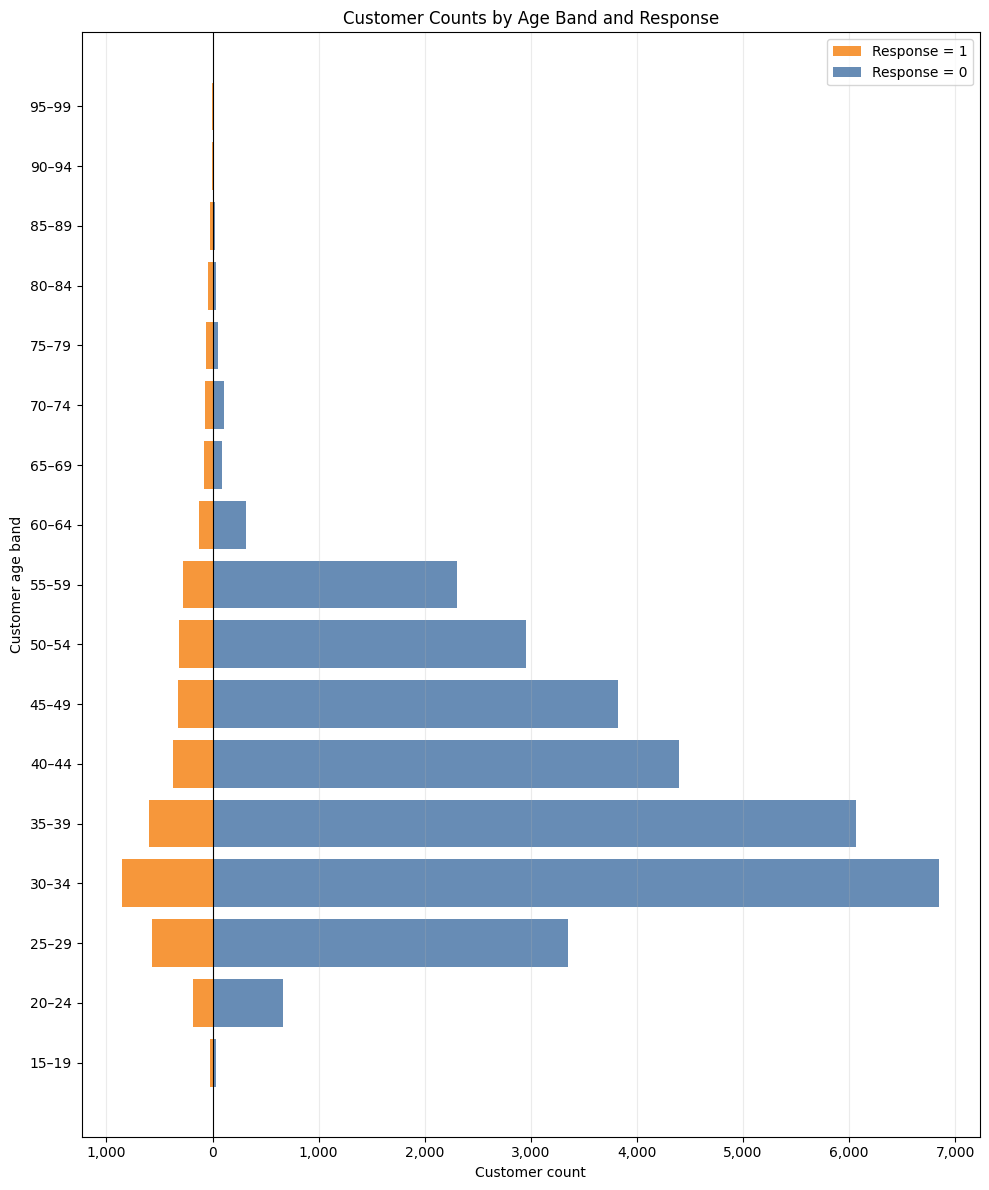

In [68]:
# Create 5-year age bands
age_min = (df["customer_age"].min() // 5) * 5
age_max = ((df["customer_age"].max() // 5) + 1) * 5
bins = np.arange(age_min, age_max + 5, 5)
age_bands = pd.cut(df["customer_age"], bins=bins, right=False)

# Count customers in each age band by response
age_distribution = pd.crosstab(age_bands, df["response"])

y = np.arange(len(age_distribution))
left = age_distribution[1].to_numpy()
right = age_distribution[0].to_numpy()

fig, ax = plt.subplots(figsize=(10, 12))
ax.barh(y, -left, color="#F58518", alpha=0.85, label="Response = 1")
ax.barh(y, right, color="#4C78A8", alpha=0.85, label="Response = 0")

ax.set_yticks(y)
ax.set_yticklabels(
    [f"{int(interval.left)}–{int(interval.right - 1)}" for interval in age_distribution.index]
)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Customer count")
ax.set_ylabel("Customer age band")
ax.set_title("Customer Counts by Age Band and Response")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{abs(x):,.0f}"))
ax.legend()
ax.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()


### last_call_duration_seconds 

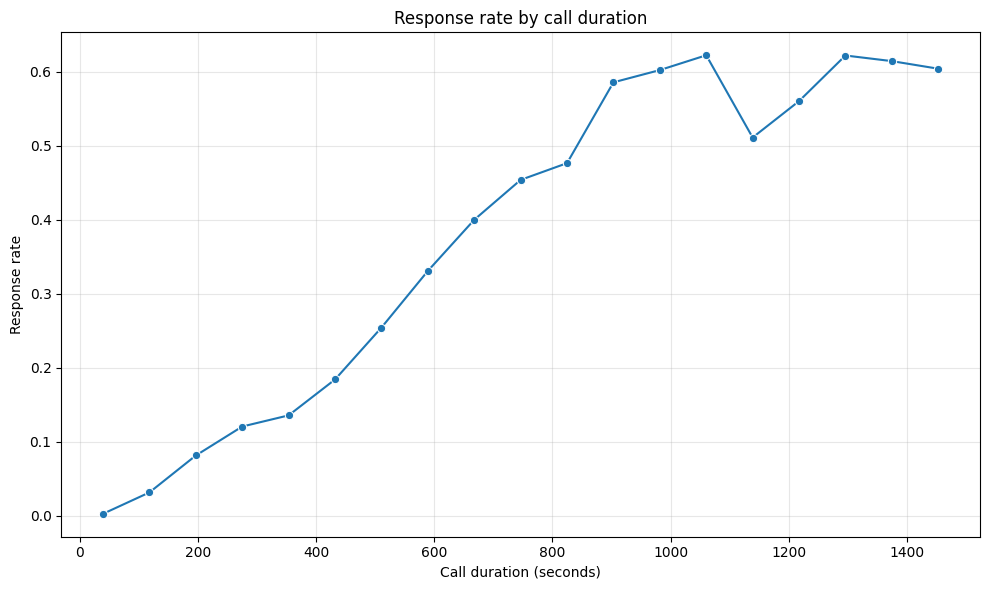

In [55]:
# Response rate by call duration
max_duration = df["last_call_duration_seconds"].quantile(0.995)
bins = np.linspace(0, max_duration, 20)

duration_bins = pd.cut(
    df["last_call_duration_seconds"],
    bins=bins,
    include_lowest=True,
    right=True
)

rate_by_duration = (
    df.assign(duration_bin=duration_bins)
      .groupby("duration_bin", observed=True)["response"]
      .mean()
      .rename("response_rate")
)

plot_df = pd.DataFrame({
    "call_duration_seconds": rate_by_duration.index.map(lambda x: x.mid),
    "response_rate": rate_by_duration.values
})

plt.figure(figsize=(10, 6))
sns.lineplot(data=plot_df, x="call_duration_seconds", y="response_rate", marker="o")
plt.xlabel("Call duration (seconds)")
plt.ylabel("Response rate")
plt.title("Response rate by call duration")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

#### days_since_last_campaign

In [41]:
is_999 = df["days_since_last_campaign"] == 999

print("Rows with 999:", is_999.sum())
print("Percentage:", round(is_999.mean() * 100, 2), "%")

print("\nThe other rows (not 999):")
print(df.loc[~is_999, "days_since_last_campaign"].describe())

Rows with 999: 33700
Percentage: 96.32 %

The other rows (not 999):
count    1289.000000
mean        6.076028
std         3.896820
min         0.000000
25%         3.000000
50%         6.000000
75%         7.000000
max        27.000000
Name: days_since_last_campaign, dtype: float64


In [42]:
print("999 vs previous_campaign_outcome:")
display(pd.crosstab(is_999, df["previous_campaign_outcome"]))

print("\n999 vs 'zero previous attempts':")
display(pd.crosstab(is_999, df["prev_campaign_call_attempts"] == 0))

999 vs previous_campaign_outcome:


previous_campaign_outcome,Cat_0_f***e,Cat_1_n***t,Cat_2_s***s
days_since_last_campaign,,,
False,127,0,1162
True,3519,30181,0



999 vs 'zero previous attempts':


prev_campaign_call_attempts,False,True
days_since_last_campaign,,
False,1289,0
True,3519,30181


In [43]:
import numpy as np

df["prev_campaign_status"] = np.select(
    [
        df["prev_campaign_call_attempts"] == 0,
        (df["prev_campaign_call_attempts"] > 0) & (df["days_since_last_campaign"] == 999),
    ],
    ["no_prev_campaign", "prev_campaign_gap_unknown"],
    default="prev_campaign_gap_known",
)

df["days_since_prev_campaign"] = df["days_since_last_campaign"].replace(999, np.nan)

print(df["prev_campaign_status"].value_counts())
print("\nMissing in days_since_prev_campaign:", df["days_since_prev_campaign"].isna().sum())

prev_campaign_status
no_prev_campaign             30181
prev_campaign_gap_unknown     3519
prev_campaign_gap_known       1289
Name: count, dtype: int64

Missing in days_since_prev_campaign: 33700


In [44]:
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)

(34989, 23)


In [45]:
print("Zero-second calls:", (df["last_call_duration_seconds"] == 0).sum())
print("Customers with > 20 call attempts:", (df["call_attempts"] > 20).sum())
print("Customers older than 80:", (df["customer_age"] > 80).sum())
print("Customers younger than 18:", (df["customer_age"] < 18).sum())

display(df[["customer_age", "last_call_duration_seconds", "call_attempts"]]
        .quantile([0.5, 0.9, 0.99, 0.999]))

Zero-second calls: 4
Customers with > 20 call attempts: 134
Customers older than 80: 96
Customers younger than 18: 4


,customer_age,last_call_duration_seconds,call_attempts
0.500,38.0,179.00,2.0
0.900,55.0,550.00,5.0
0.990,71.0,1268.00,14.0
0.999,86.0,2129.12,29.0


## Categirical Variables 

In [46]:
cat_cols = df.select_dtypes(include="str").columns

for col in cat_cols:
    print(f"\n{col}")
    print(df[col].value_counts())


employment_type
employment_type
Cat_0_a***.     8864
Cat_1_b***r     7857
Cat_9_t***n     5733
Cat_7_s***s     3351
Cat_4_m***t     2489
Cat_5_r***d     1464
Cat_2_e***r     1256
Cat_6_s***d     1215
Cat_3_h***d      901
Cat_10_u***d     839
Cat_8_s***t      727
Cat_11_u***n     293
Name: count, dtype: int64

customer_civil_status
customer_civil_status
Cat_1_m***d    21206
Cat_2_s***e     9812
Cat_0_d***d     3902
Cat_3_u***n       69
Name: count, dtype: int64

education_level
education_level
Cat_6_u***e    10309
Cat_3_h***l     8039
Cat_2_b***y     5176
Cat_5_p***e     4477
Cat_0_b***y     3533
Cat_1_b***y     1962
Cat_7_u***n     1476
Cat_4_i***e       17
Name: count, dtype: int64

credit_facility_default
credit_facility_default
Cat_0_n***o    27664
Cat_1_u***n     7322
Cat_2_y***s        3
Name: count, dtype: int64

has_home_loan
has_home_loan
Cat_2_y***s    18287
Cat_0_n***o    15863
Cat_1_u***n      839
Name: count, dtype: int64

has_personal_loan
has_personal_loan
Cat_0_n***o   

In [47]:
home_unk = df["has_home_loan"] == "Cat_1_u***n"
pers_unk = df["has_personal_loan"] == "Cat_1_u***n"
emp_839  = df["employment_type"] == "Cat_10_u***d"

print("home unknown vs personal unknown:")
display(pd.crosstab(home_unk, pers_unk))

print("\nhome unknown vs employment Cat_10_u***d:")
display(pd.crosstab(home_unk, emp_839))

home unknown vs personal unknown:


has_personal_loan,False,True
has_home_loan,,
False,34150,0
True,0,839



home unknown vs employment Cat_10_u***d:


employment_type,False,True
has_home_loan,,
False,33331,819
True,819,20


# Pre-training

## Splitting the Dataset 

In [48]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["response"])
y = df["response"]

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

for name, part in [("train", y_train), ("val", y_val), ("test", y_test)]:
    print(f"{name}: {len(part):,} rows, {part.sum():,} responders, rate = {part.mean():.4f}")

# Safety check: no row belongs to two sets
print("\nOverlap train/val:", len(set(X_train.index) & set(X_val.index)))
print("Overlap train/test:", len(set(X_train.index) & set(X_test.index)))
print("Overlap val/test:", len(set(X_val.index) & set(X_test.index)))

train: 24,492 rows, 2,750 responders, rate = 0.1123
val: 5,248 rows, 589 responders, rate = 0.1122
test: 5,249 rows, 590 responders, rate = 0.1124

Overlap train/val: 0
Overlap train/test: 0
Overlap val/test: 0


In [49]:
train = X_train.assign(response=y_train)

print("Training response rate:", round(train["response"].mean(), 4))

summary = (
    train.groupby("prev_campaign_status")["response"]
    .agg(customers="size", responders="sum", response_rate="mean")
    .round(3)
)
display(summary)

Training response rate: 0.1123


,customers,responders,response_rate
prev_campaign_status,,,
no_prev_campaign,21145,1864,0.088
prev_campaign_gap_known,892,568,0.637
prev_campaign_gap_unknown,2455,318,0.130


In [50]:
print("Customers:")
display(pd.crosstab(train["prev_campaign_status"], train["previous_campaign_outcome"],
                    margins=True, margins_name="Total"))

print("\nResponse rate:")
display(pd.crosstab(train["prev_campaign_status"], train["previous_campaign_outcome"],
                    values=train["response"], aggfunc="mean").round(3))

Customers:


previous_campaign_outcome,Cat_0_f***e,Cat_1_n***t,Cat_2_s***s,Total
prev_campaign_status,,,,
no_prev_campaign,0,21145,0,21145
prev_campaign_gap_known,90,0,802,892
prev_campaign_gap_unknown,2455,0,0,2455
Total,2545,21145,802,24492



Response rate:


previous_campaign_outcome,Cat_0_f***e,Cat_1_n***t,Cat_2_s***s
prev_campaign_status,,,
no_prev_campaign,NaN,0.088,NaN
prev_campaign_gap_known,0.50,NaN,0.652
prev_campaign_gap_unknown,0.13,NaN,NaN


In [51]:
num_cols = [
    "customer_age", "last_call_duration_seconds", "call_attempts",
    "days_since_prev_campaign", "prev_campaign_call_attempts",
    "employment_variation_rate_q", "consumer_price_index_m",
    "consumer_confidence_index_m", "interbank_rate_3m_q", "num_employees_q",
]

medians = train.groupby("response")[num_cols].median().T
medians.columns = ["median if no response (0)", "median if response (1)"]
display(medians.round(2))

,median if no response (0),median if response (1)
customer_age,38.00,37.00
last_call_duration_seconds,162.00,460.00
call_attempts,2.00,1.00
days_since_prev_campaign,6.00,6.00
prev_campaign_call_attempts,0.00,0.00
employment_variation_rate_q,1.10,-1.80
consumer_price_index_m,93.92,93.20
consumer_confidence_index_m,-41.80,-40.80
interbank_rate_3m_q,4.86,1.27
num_employees_q,5195.80,5099.10


In [52]:
macro = [
    "employment_variation_rate_q", "consumer_price_index_m",
    "consumer_confidence_index_m", "interbank_rate_3m_q", "num_employees_q",
]

display(train[macro + ["response"]].corr().round(2))

,employment_variation_rate_q,consumer_price_index_m,consumer_confidence_index_m,interbank_rate_3m_q,num_employees_q,response
employment_variation_rate_q,1.00,0.77,0.21,0.97,0.91,-0.29
consumer_price_index_m,0.77,1.00,0.07,0.69,0.52,-0.13
consumer_confidence_index_m,0.21,0.07,1.00,0.29,0.11,0.05
interbank_rate_3m_q,0.97,0.69,0.29,1.00,0.95,-0.30
num_employees_q,0.91,0.52,0.11,0.95,1.00,-0.35
response,-0.29,-0.13,0.05,-0.30,-0.35,1.00
